## Lab 6: $k$-means
You can use external libraries for linear algebra operations (e.g. `numpy`) but you are expected to write your own algorithms. In this notebook `sklearn` is used only to **check** our implementations, never to produce the results.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import OrdinalEncoder

np.random.seed(42)

# Exercise 1
- Load the `breast_cancer.csv` dataset (Datasets folder; original data at https://archive.ics.uci.edu/ml/datasets/Breast+Cancer) and preprocess it with `sklearn.preprocessing.OrdinalEncoder` to properly deal with the categorical variables.

In [2]:
df = pd.read_csv("../Datasets/breast_cancer.csv", header=None)
df = df.astype(str)          # every column is categorical (also the ordered ones, e.g. age ranges)
df = df.fillna("missing")    # depending on the pandas version astype(str) may keep NaN; encode them as a category
df.head()

,0,1,2,3,4,5,6,7,8,9
0,'40-49','premeno','15-19','0-2','yes','3','right','left_up','no','recurrence-events'
1,'50-59','ge40','15-19','0-2','no','1','right','central','no','no-recurrence-events'
2,'50-59','ge40','35-39','0-2','no','2','left','left_low','no','recurrence-events'
3,'40-49','premeno','35-39','0-2','yes','3','right','left_low','yes','no-recurrence-events'
4,'40-49','premeno','30-34','3-5','yes','2','left','right_up','no','recurrence-events'


In [3]:
feature_names = ['age', 'menopause', 'tumor-size', 'inv-nodes', 'node-caps',
                 'deg-malig', 'breast', 'breast-quad', 'irradiat']
# Attribute information from https://archive.ics.uci.edu/ml/datasets/Breast+Cancer
# The last column is the class: no-recurrence-events / recurrence-events

print(df.isna().sum().sum(), "NaN values")
print("Missing entries per column:\n", ((df == "'?'") | (df == "missing")).sum())

0 NaN values
Missing entries per column:
 0    0
1    0
2    0
3    0
4    8
5    0
6    0
7    1
8    0
9    0
dtype: int64


In [4]:
encoder = OrdinalEncoder()
data = encoder.fit_transform(df)

X = data[:, :9]   # covariates
y = data[:, 9]    # response, encoded in the same step
print(X.shape, y.shape, np.unique(y, return_counts=True))

(286, 9) (286,) (array([0., 1.]), array([201,  85]))


- Write your own function to compute the Mutual Information criterion.
- Compute the Mutual Information between the covariates and the response variable (last column). Which features appear to be the most significant?

For two discrete variables $X$, $Y$:
$$I(X;Y)=\sum_{x}\sum_{y} p(x,y)\log\frac{p(x,y)}{p(x)\,p(y)} .$$
The probabilities are estimated with the empirical frequencies (contingency table).

In [5]:
def mutual_information(x, y):
    """Mutual information (in nats) between two discrete 1D arrays, from empirical frequencies."""
    x_vals, x_idx = np.unique(x, return_inverse=True)
    y_vals, y_idx = np.unique(y, return_inverse=True)

    # joint frequency table
    joint = np.zeros((len(x_vals), len(y_vals)))
    np.add.at(joint, (x_idx, y_idx), 1)
    pxy = joint / joint.sum()

    px = pxy.sum(axis=1, keepdims=True)   # marginal of x (column vector)
    py = pxy.sum(axis=0, keepdims=True)   # marginal of y (row vector)

    nz = pxy > 0                          # convention: 0 log 0 = 0
    return np.sum(pxy[nz] * np.log(pxy[nz] / (px @ py)[nz]))

In [6]:
MI = np.array([mutual_information(X[:, j], y) for j in range(X.shape[1])])
pd.Series(MI, index=feature_names).sort_values(ascending=False)

deg-malig      0.053379
inv-nodes      0.047824
tumor-size     0.039628
node-caps      0.037030
irradiat       0.017896
breast-quad    0.010443
age            0.007351
breast         0.001725
menopause      0.001387
dtype: float64

In [7]:
# Check against sklearn (only for validation)
from sklearn.feature_selection import mutual_info_classif
MI_sk = mutual_info_classif(X, y, discrete_features=True)
print("max abs difference with sklearn:", np.abs(MI - MI_sk).max())

max abs difference with sklearn: 6.453171330633722e-16


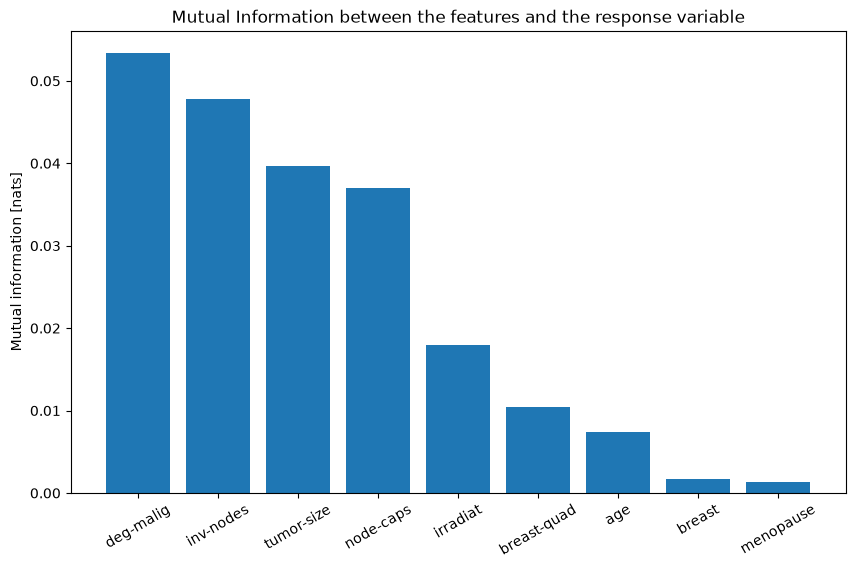

In [8]:
plt.figure(figsize=(10, 6))
order = np.argsort(MI)[::-1]
plt.bar(np.array(feature_names)[order], MI[order])
plt.xticks(rotation=30)
plt.ylabel("Mutual information [nats]")
plt.title("Mutual Information between the features and the response variable")
plt.show()

**Discussion.** The most informative features are the ones at the top of the ranking (here `deg-malig`, `inv-nodes`, `tumor-size` and `node-caps`, followed by `irradiat`, carry the most information about recurrence), while `breast`, `menopause` and `age` are almost independent of the response. 

Be careful: the plug-in estimator of the MI is **biased upwards for variables with many categories** (e.g. `tumor-size` has 12 values, `breast` only 2) on a small sample (286 rows). A feature can look informative just because it has many levels.

# Exercise 2
- Use the dataset `s3.txt` in the `Datasets` folder.

(5000, 2)


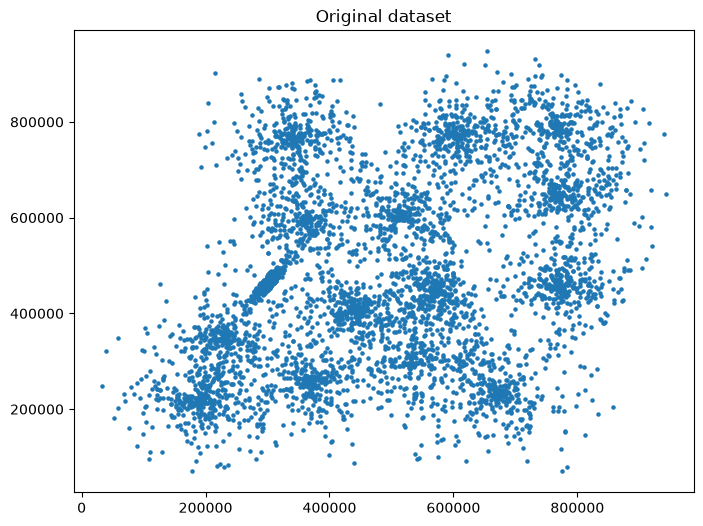

In [9]:
s3 = np.genfromtxt("../Datasets/s3.txt")
print(s3.shape)

plt.figure(figsize=(8, 6))
plt.scatter(s3[:, 0], s3[:, 1], s=5)
plt.title("Original dataset")
plt.show()

- Write your own implementation of the $k$-means clustering algorithm.
- Test your implementation with 10 different initializations and $k=15$.

$k$-means (Lloyd's algorithm) minimises the loss $L=\sum_{i}\|x_i-\mu_{c(i)}\|^2$ by alternating: (1) **assignment** of every point to its closest centroid; (2) **update** of every centroid to the mean of its points. We stop when the assignments do not change anymore. The initial centroids are $k$ points drawn at random from the dataset.

We vectorise the distance computation: $\|x-\mu\|^2=\|x\|^2-2x\cdot\mu+\|\mu\|^2$.

In [10]:
def kmeans(X, k, max_iter=300, rng=None):
    """Lloyd's k-means. Returns labels, centroids, final loss and the loss history."""
    rng = np.random.default_rng() if rng is None else rng
    n = X.shape[0]
    sq_norm = (X ** 2).sum(axis=1, keepdims=True)

    def sq_dist(C):   # (n, k) matrix of squared distances, no python loops
        return sq_norm - 2 * X @ C.T + (C ** 2).sum(axis=1)

    centroids = X[rng.choice(n, size=k, replace=False)].copy()   # k random data points

    labels, history = None, []
    for it in range(max_iter):
        D = sq_dist(centroids)
        new_labels = D.argmin(axis=1)                                  # assignment step
        history.append(D[np.arange(n), new_labels].sum())
        if labels is not None and np.array_equal(new_labels, labels):  # converged
            break
        labels = new_labels
        for j in range(k):                                             # update step
            members = X[labels == j]
            if len(members) > 0:                                       # keep old centroid if the cluster is empty
                centroids[j] = members.mean(axis=0)
    loss = ((X - centroids[labels]) ** 2).sum()
    return labels, centroids, loss, history

In [11]:
k = 15
results = []
for i in range(10):
    labels, centroids, loss, history = kmeans(s3, k, rng=np.random.default_rng(i))
    results.append((loss, labels, centroids, history))
    print(f"init {i}: loss = {loss:.4e}, iterations = {len(history)}")

init 0: loss = 2.0914e+13, iterations = 19
init 1: loss = 2.0774e+13, iterations = 24
init 2: loss = 1.8755e+13, iterations = 40
init 3: loss = 1.9083e+13, iterations = 21
init 4: loss = 2.1200e+13, iterations = 49
init 5: loss = 1.8895e+13, iterations = 44
init 6: loss = 1.8694e+13, iterations = 47
init 7: loss = 1.8671e+13, iterations = 23
init 8: loss = 1.6890e+13, iterations = 26
init 9: loss = 2.0892e+13, iterations = 45


In [12]:
# Sanity check against sklearn: same initial centroids -> same result
from sklearn.cluster import KMeans
rng = np.random.default_rng(0)
init_c = s3[rng.choice(len(s3), size=k, replace=False)]
km = KMeans(n_clusters=k, init=init_c, n_init=1, algorithm="lloyd", tol=0, max_iter=300).fit(s3)
print("sklearn inertia:", km.inertia_, " ours:", results[0][0])

sklearn inertia: 20913670129017.23  ours: 20913670129017.234


- Plot the clustering results for which the loss is, respectively, the highest and the lowest.

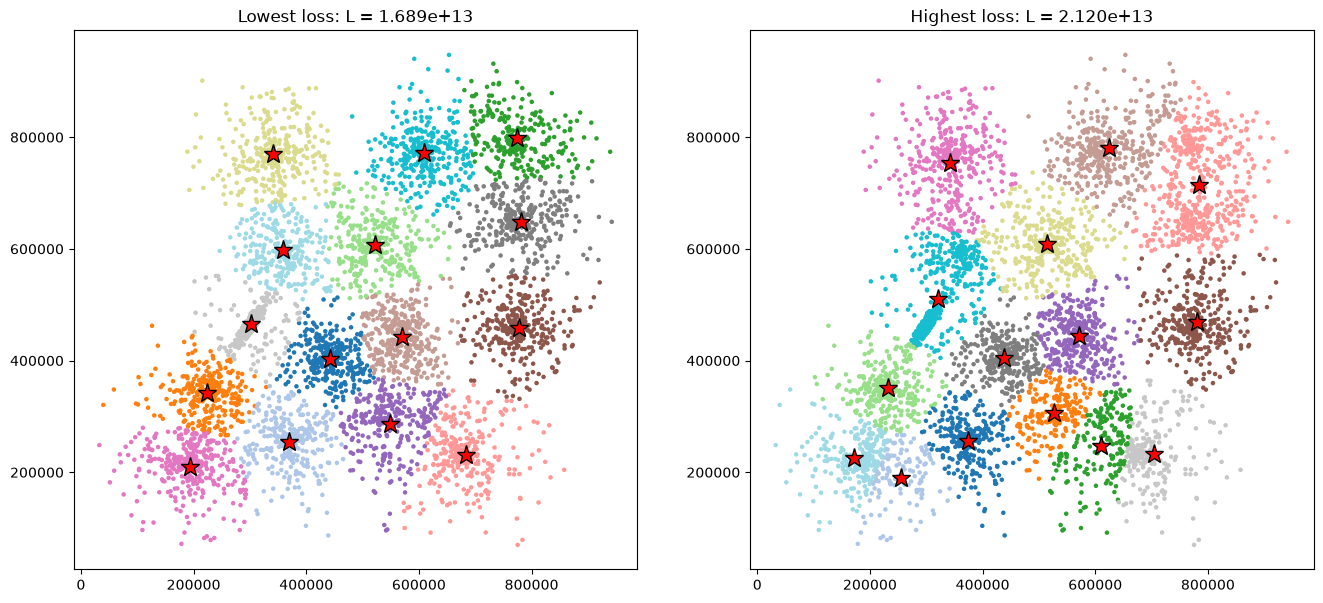

In [13]:
order = np.argsort([r[0] for r in results])
best, worst = results[order[0]], results[order[-1]]

fig, axs = plt.subplots(1, 2, figsize=(16, 7))
for ax, (loss, labels, cents, _), name in zip(axs, [best, worst], ["Lowest loss", "Highest loss"]):
    ax.scatter(s3[:, 0], s3[:, 1], c=labels, cmap="tab20", s=5)
    ax.plot(cents[:, 0], cents[:, 1], "r*", markersize=14, markeredgecolor="k")
    ax.set_title(f"{name}: L = {loss:.3e}")
plt.show()

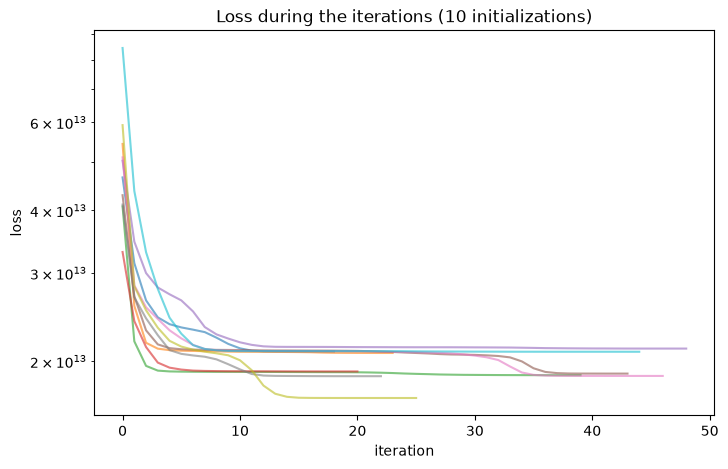

In [14]:
plt.figure(figsize=(8, 5))
for loss, _, _, h in results:
    plt.plot(h, alpha=0.6)
plt.yscale("log"); plt.xlabel("iteration"); plt.ylabel("loss")
plt.title("Loss during the iterations (10 initializations)")
plt.show()

**Discussion.** The loss never increases during the iterations, so $k$-means always converges, but only to a *local* minimum that depends on the initialization: the 10 final losses differ by about 25%. $s3$ has 15 clusters of different overlap; with a bad random initialization some true clusters receive two centroids while other (close) clusters are forced to share one, and the loss is higher. Running several initializations and keeping the one with the lowest loss is therefore standard practice.